In [1]:
import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
for p in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(p, quiet=True)

In [2]:
corpus = {
    "symptom_info": [
        "what are the early symptoms of diabetes",
        "why do i feel very thirsty and urinate often",
        "what is the difference between type 1 and type 2 diabetes",
        "what causes type 2 diabetes",
        "is blurred vision a sign of high blood sugar",
        "what is prediabetes",
        "how is diabetes diagnosed",
        "can diabetes run in the family",
        "why do my wounds heal so slowly",
        "what is gestational diabetes",
        "i feel tired and hungry all the time could it be diabetes",
        "is diabetes curable",
        "what are the signs of diabetes in children",
        "how do i know if i am prediabetic",
        "what are the warning signs of type 2 diabetes",
        "can too much sugar cause diabetes",
        "what are the symptoms of type 1 diabetes in adults",
        "why am i losing weight even though i eat a lot",
        "does tingling in the hands and feet mean diabetes",
        "what blood test confirms diabetes",
        "what is the difference between prediabetes and diabetes",
        "are frequent infections a symptom of diabetes",
    ],
    "blood_sugar_monitoring": [
        "what is a normal fasting blood sugar level",
        "how often should i check my blood sugar",
        "what is the hba1c test",
        "what should my blood sugar be after meals",
        "how do i use a glucometer",
        "what is a good hba1c target for a diabetic",
        "when is the best time to test blood glucose",
        "what does a high fasting sugar reading mean",
        "how often should i get my hba1c checked",
        "what is a continuous glucose monitor",
        "why is my morning blood sugar high",
        "what blood sugar level is considered low",
        "how can i keep a record of my sugar readings",
        "is it normal for blood sugar to rise after eating",
        "what is the normal range for random blood sugar",
        "how do i read my glucose meter result",
        "should i test my sugar before or after meals",
        "what hba1c level means good control",
        "why does my sugar spike in the morning",
        "how many times a day should i test my glucose",
        "what does an hba1c of 8 mean",
        "how accurate are home glucose meters",
    ],
    "medication_insulin": [
        "how does metformin work",
        "what are the side effects of metformin",
        "when should i take my insulin injection",
        "how should i store insulin at home",
        "what happens if i miss a dose of my diabetes tablet",
        "can i stop taking my diabetes medicine if my sugar is normal",
        "what are the different types of insulin",
        "how do i inject insulin correctly",
        "which areas of the body are used for insulin injection",
        "can i take diabetes tablets with food",
        "what is the difference between rapid and long acting insulin",
        "does insulin cause weight gain",
        "can i drink alcohol while taking metformin",
        "how long does insulin take to start working",
        "what is the starting dose of metformin",
        "can i take insulin and tablets together",
        "how do i dispose of used insulin needles",
        "what are the common side effects of diabetes tablets",
        "should i inject insulin before or after meals",
        "what should i do if i forget my insulin",
        "can type 2 diabetes be treated without insulin",
        "what is an insulin pen and how does it work",
    ],
    "diet_nutrition": [
        "what foods should a diabetic avoid",
        "is rice safe for diabetics",
        "which fruits are good for diabetes",
        "what is a good breakfast for a diabetic",
        "how many carbohydrates should i eat per day",
        "what is the glycemic index",
        "can diabetics eat sweets occasionally",
        "is it ok to eat bananas with diabetes",
        "what snacks are good for blood sugar control",
        "are artificial sweeteners safe for diabetics",
        "should i eat small meals more often",
        "is roti better than rice for diabetes",
        "can i drink fruit juice if i have diabetes",
        "what should i eat when i eat out with diabetes",
        "what are the best vegetables for diabetes",
        "is brown rice better than white rice for sugar control",
        "can diabetics eat potatoes",
        "what is a healthy diabetic diet plan for a day",
        "is honey safe for people with diabetes",
        "how much sugar can a diabetic eat in a day",
        "are millets good for diabetes",
        "should diabetics eat dry fruits",
    ],
    "lifestyle_exercise": [
        "what exercise is good for diabetes",
        "how much walking should a diabetic do daily",
        "does yoga help control blood sugar",
        "how does stress affect blood sugar",
        "how does sleep affect diabetes",
        "can i lose weight to reverse type 2 diabetes",
        "should i check my sugar before exercising",
        "does smoking make diabetes worse",
        "how can i prevent diabetes if it runs in my family",
        "how can i manage diabetes while travelling",
        "is it safe to fast with diabetes",
        "how can i stay active with a desk job and diabetes",
        "what lifestyle changes help control diabetes",
        "does drinking water help lower blood sugar",
        "is jogging good for diabetes",
        "how long should i exercise to lower blood sugar",
        "does weight loss improve insulin sensitivity",
        "what time of day is best to exercise for diabetes",
        "can lack of sleep raise blood sugar",
        "does meditation help with diabetes",
        "how can i stay motivated to stay active with diabetes",
        "how do i prevent diabetes at a young age",
    ],
    "complications_care": [
        "how do i take care of my feet with diabetes",
        "how does diabetes affect the eyes",
        "what are the signs of diabetic kidney disease",
        "what should i do when my blood sugar is too low",
        "what is hypoglycemia",
        "how can i prevent diabetic neuropathy",
        "why do diabetics get numbness in the feet",
        "how often should a diabetic get an eye exam",
        "what are sick day rules for diabetes",
        "how can diabetes harm the heart",
        "what should i do if my sugar is very high",
        "how to treat a foot ulcer in a diabetic",
        "how can i protect my kidneys if i have diabetes",
        "what is the 15 15 rule for low sugar",
        "what should i do if my feet tingle and burn",
        "how do i know if diabetes is damaging my kidneys",
        "how do i treat low blood sugar at home",
        "what are the symptoms of low blood sugar",
        "how does high sugar damage the nerves",
        "which doctor should i see for diabetic eye problems",
        "how do i care for a cut on my foot if i am diabetic",
        "what is diabetic retinopathy",
    ],
}
df = pd.DataFrame([(q, k) for k, v in corpus.items() for q in v], columns=["text", "intent"])
print(df.shape)
print(df["intent"].value_counts())

(132, 2)
intent
symptom_info              22
blood_sugar_monitoring    22
medication_insulin        22
diet_nutrition            22
lifestyle_exercise        22
complications_care        22
Name: count, dtype: int64


In [3]:
taxonomy = {
    "Understanding Diabetes": {"Types and Causes": "symptom_info", "Symptoms and Diagnosis": "symptom_info"},
    "Monitoring and Treatment": {"Blood Sugar Monitoring": "blood_sugar_monitoring", "Medication and Insulin": "medication_insulin"},
    "Lifestyle Management": {"Diet and Nutrition": "diet_nutrition", "Exercise and Daily Habits": "lifestyle_exercise"},
    "Complications and Care": {"Foot, Eye and Kidney Care": "complications_care", "Low and High Sugar Management": "complications_care"},
}
intent_path = {}
for cat, subs in taxonomy.items():
    print(cat)
    for sub, intent in subs.items():
        print("   -", sub, "->", intent)
        intent_path.setdefault(intent, f"{cat} > {sub}")

Understanding Diabetes
   - Types and Causes -> symptom_info
   - Symptoms and Diagnosis -> symptom_info
Monitoring and Treatment
   - Blood Sugar Monitoring -> blood_sugar_monitoring
   - Medication and Insulin -> medication_insulin
Lifestyle Management
   - Diet and Nutrition -> diet_nutrition
   - Exercise and Daily Habits -> lifestyle_exercise
Complications and Care
   - Foot, Eye and Kidney Care -> complications_care
   - Low and High Sugar Management -> complications_care


11 concepts, 13 relationships


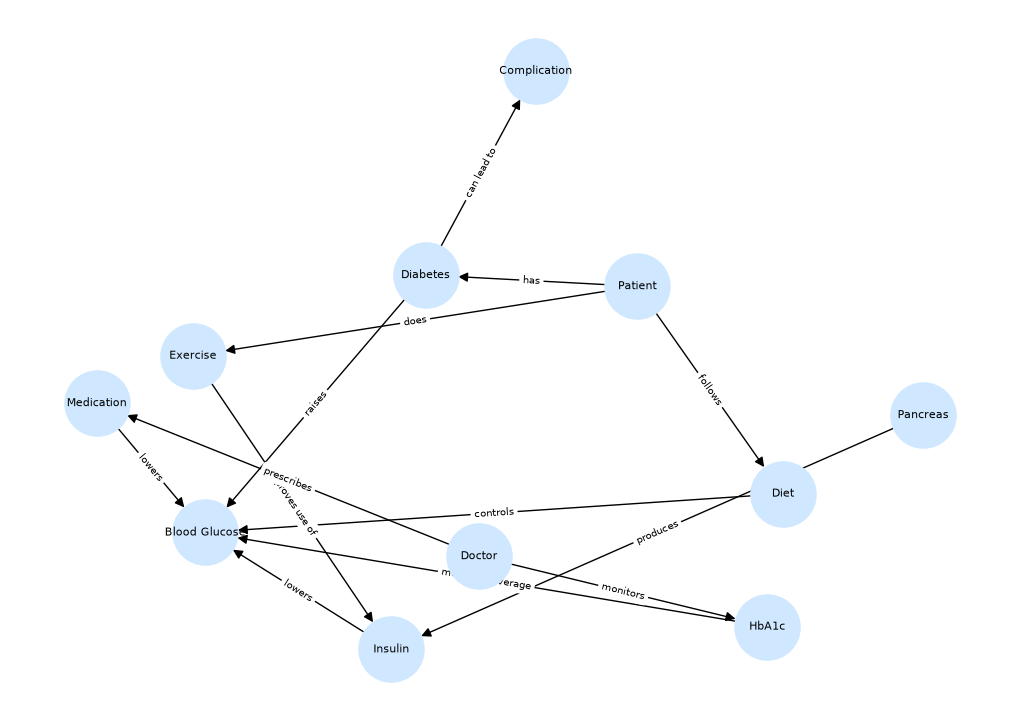

In [4]:
import networkx as nx

concepts = ["Patient", "Diabetes", "Pancreas", "Insulin", "Blood Glucose", "HbA1c", "Medication", "Diet", "Exercise", "Complication", "Doctor"]

relations = [
    ["Patient", "has", "Diabetes"],
    ["Pancreas", "produces", "Insulin"],
    ["Insulin", "lowers", "Blood Glucose"],
    ["Diabetes", "raises", "Blood Glucose"],
    ["Medication", "lowers", "Blood Glucose"],
    ["HbA1c", "measures average", "Blood Glucose"],
    ["Diet", "controls", "Blood Glucose"],
    ["Exercise", "improves use of", "Insulin"],
    ["Doctor", "prescribes", "Medication"],
    ["Doctor", "monitors", "HbA1c"],
    ["Diabetes", "can lead to", "Complication"],
    ["Patient", "follows", "Diet"],
    ["Patient", "does", "Exercise"],
]
print(len(concepts), "concepts,", len(relations), "relationships")

G = nx.DiGraph()
for a, r, b in relations:
    G.add_edge(a, b, label=r)
pos = nx.spring_layout(G, seed=3, k=1.2)
plt.figure(figsize=(10, 7))
nx.draw(G, pos, with_labels=True, node_color="#cfe8ff", node_size=2200, font_size=8, arrowsize=14)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "label"), font_size=7)
plt.show()

In [5]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop = set(stopwords.words("english"))
lem = WordNetLemmatizer()

def preprocess(text):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha() and t not in stop]
    return " ".join(lem.lemmatize(lem.lemmatize(t), "v") for t in tokens)

df["clean"] = df["text"].apply(preprocess)
print(df[["text", "clean"]].head(5).to_string())

                                                        text                              clean
0                    what are the early symptoms of diabetes             early symptom diabetes
1               why do i feel very thirsty and urinate often         feel thirsty urinate often
2  what is the difference between type 1 and type 2 diabetes      difference type type diabetes
3                                what causes type 2 diabetes                cause type diabetes
4               is blurred vision a sign of high blood sugar  blur vision sign high blood sugar


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["intent"], test_size=0.25, stratify=df["intent"], random_state=42)

candidates = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(C=10, max_iter=1000),
    "SVM": LinearSVC(),
}
for name, clf in candidates.items():
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), clf)
    cv = cross_val_score(pipe, df["clean"], df["intent"], cv=5)
    print(f"{name:20} cv accuracy = {cv.mean():.3f}")

# logistic regression is used in the assistant because it gives probabilities (needed for the confidence rule)
model = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(C=10, max_iter=1000))
model.fit(X_train, y_train)

Naive Bayes          cv accuracy = 0.675
Logistic Regression  cv accuracy = 0.705
SVM                  cv accuracy = 0.705


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidfvectorizer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](6,)","['blood_sugar_monitoring','complications_care','diet_nutrition', 'lifestyle_exercise','medication_insulin','symptom_info']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None


accuracy : 0.727
precision: 0.743
recall   : 0.727
f1-score : 0.721 

                        precision    recall  f1-score   support

blood_sugar_monitoring       0.67      0.80      0.73         5
    complications_care       0.67      0.80      0.73         5
        diet_nutrition       0.75      0.50      0.60         6
    lifestyle_exercise       0.75      0.50      0.60         6
    medication_insulin       1.00      1.00      1.00         6
          symptom_info       0.57      0.80      0.67         5

              accuracy                           0.73        33
             macro avg       0.73      0.73      0.72        33
          weighted avg       0.74      0.73      0.72        33



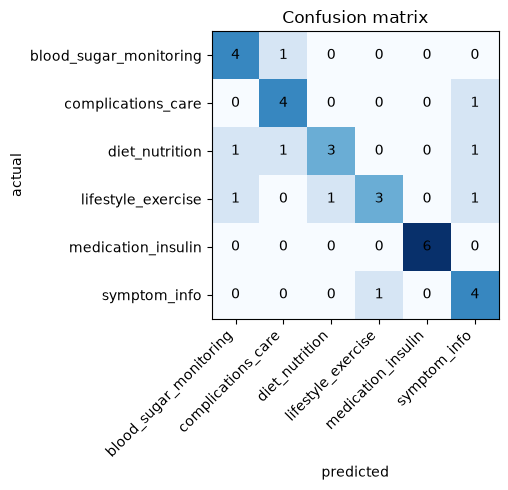

In [7]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

pred = model.predict(X_test)
p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="weighted", zero_division=0)
print("accuracy :", round(accuracy_score(y_test, pred), 3))
print("precision:", round(p, 3))
print("recall   :", round(r, 3))
print("f1-score :", round(f, 3), "\n")
print(classification_report(y_test, pred, zero_division=0))

labels = model.classes_
cm = confusion_matrix(y_test, pred, labels=labels)
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(len(labels)), labels, rotation=45, ha="right")
plt.yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.xlabel("predicted")
plt.ylabel("actual")
plt.title("Confusion matrix")
plt.tight_layout()
plt.show()

In [8]:
from sklearn.metrics.pairwise import linear_kernel

kb = {
    "symptom_info": [
        ("general", "symptoms diabetes early sign thirst urination hunger tired blurred",
         "Common early signs of diabetes are increased thirst, frequent urination, constant hunger, tiredness, blurred vision and slow healing wounds. Diabetes is confirmed with blood tests, so please get tested if you notice these signs."),
        ("types", "type 1 type 2 difference insulin",
         "Type 1 diabetes happens when the body makes little or no insulin and usually starts early in life. Type 2 is much more common: the body does not use insulin well, and it is linked to age, weight, inactivity and family history."),
        ("causes", "cause causes type 2 family genes run",
         "Type 2 diabetes develops from a mix of genes, excess body fat, low physical activity and age. A family history raises the risk, but lifestyle changes can lower it."),
        ("prediabetes", "prediabetes prediabetic borderline",
         "Prediabetes means blood sugar is higher than normal but not yet in the diabetes range. It can often be reversed with weight loss, regular exercise and a better diet."),
        ("diagnosis", "diagnose diagnosed test fasting hba1c glucose tolerance",
         "Diabetes is usually diagnosed with a fasting blood sugar of 126 mg/dL or higher, an HbA1c of 6.5% or higher, or a 2-hour glucose tolerance test of 200 mg/dL or higher. A doctor confirms the result with a repeat test."),
        ("gestational", "gestational pregnancy pregnant",
         "Gestational diabetes is high blood sugar first found during pregnancy. It usually goes away after delivery but raises the future risk of type 2 diabetes, so follow-up testing is needed."),
        ("children and cure", "child children kids cure curable remission",
         "In children, warning signs include extra thirst, frequent urination, bedwetting, weight loss and tiredness. Type 1 diabetes has no cure and needs insulin, while type 2 can go into remission in some people with weight loss but still needs regular monitoring."),
    ],
    "blood_sugar_monitoring": [
        ("general", "blood sugar check monitor record log reading",
         "Checking blood sugar shows how food, activity and medicine affect you. Keep a log of your readings and share it with your doctor."),
        ("targets", "normal fasting after meals target level range",
         "For most adults, a usual fasting target is 80 to 130 mg/dL and under 180 mg/dL about 2 hours after a meal. Your doctor may set different targets for you."),
        ("hba1c", "hba1c a1c average three months",
         "HbA1c shows your average blood sugar over the last 2 to 3 months. Many adults aim for below 7%, and it is usually checked every 3 to 6 months."),
        ("how often", "often frequency test time best when",
         "How often to test depends on your treatment. People on insulin often test several times a day, while others may test less often. Ask your doctor for your own schedule."),
        ("glucometer", "glucometer meter strip prick finger use",
         "Wash and dry your hands, insert a strip, prick the side of a fingertip and touch the drop to the strip. Note the reading and use strips before their expiry date."),
        ("continuous monitor", "continuous glucose monitor cgm sensor",
         "A continuous glucose monitor has a small sensor under the skin that reads glucose every few minutes and shows trends. It can reduce the number of finger pricks."),
        ("morning high", "morning high fasting reading rise eating",
         "A high morning sugar can be due to hormones released overnight, a late heavy dinner or missed medicine. Sugar also rises normally after eating. Tell your doctor if high mornings keep happening so treatment can be adjusted."),
        ("low level", "low hypoglycemia below 70",
         "A blood sugar below 70 mg/dL is considered low. Treat it at once with fast sugar and recheck."),
    ],
    "medication_insulin": [
        ("general", "medicine medication tablet diabetes",
         "Take diabetes medicines exactly as your doctor prescribed. Do not change the dose by yourself, and ask your doctor or pharmacist if you are unsure."),
        ("metformin", "metformin work side effect nausea tablet",
         "Metformin lowers sugar by reducing the sugar made by the liver and helping the body use insulin better. Common side effects are nausea, loose stools and stomach upset, which often improve when it is taken with meals."),
        ("insulin types", "insulin type rapid long acting working start",
         "Rapid-acting insulin starts working within about 15 minutes and is taken with meals. Long-acting insulin works through the day and night. Your doctor chooses a combination to suit you."),
        ("injection", "inject injection site area abdomen thigh arm needle",
         "Insulin is injected into the fat under the skin of the abdomen, thigh or upper arm, and the sites should be rotated. Use a new needle each time and follow your doctor's instructions on dose and timing."),
        ("storage", "store storage fridge keep",
         "Keep unopened insulin in a fridge and the pen or vial in use at room temperature, away from heat and sunlight. Never freeze it, and check the expiry date."),
        ("missed dose and stopping", "miss missed dose forget stop normal",
         "If you miss a dose, follow the instructions for your medicine or ask your doctor, and do not double the next dose. Never stop diabetes medicine because your sugar looks normal, because the numbers are normal due to the medicine."),
        ("alcohol and weight", "alcohol drink weight gain food meals",
         "Alcohol can cause low blood sugar, especially with insulin, so limit it and never drink on an empty stomach. Heavy drinking with metformin also raises the risk of lactic acidosis. Insulin can cause some weight gain, which diet and activity can limit."),
    ],
    "diet_nutrition": [
        ("general", "diet food eat meal healthy",
         "Eat regular meals with vegetables, whole grains, protein and healthy fats, and limit sugary drinks, sweets and refined flour."),
        ("foods to avoid", "avoid sugar sweets white bread fried packaged",
         "Limit sugary drinks, sweets, white bread, fried snacks and packaged foods with added sugar. Choose whole grains, vegetables, pulses and lean protein instead."),
        ("carbs and gi", "carbohydrate carb glycemic index low gi oats millets",
         "Carbohydrates raise blood sugar the most. Low glycemic index foods such as oats, millets, pulses and most vegetables raise it more slowly. A dietitian can set a carbohydrate target for you."),
        ("rice and roti", "rice roti chapati grain portion brown",
         "Portion size matters more than the grain. Eat smaller portions of rice or roti with plenty of vegetables, dal and protein, and prefer whole grains like brown rice, millets or whole wheat."),
        ("fruit and juice", "fruit juice banana apple guava papaya",
         "Whole fruits like apples, guavas, berries, oranges and papaya are fine in measured portions. Eat the fruit instead of drinking juice, because juice raises sugar quickly. A banana is fine in small portions."),
        ("breakfast and snacks", "breakfast snack nuts chana sprouts oats",
         "Good breakfast choices are a vegetable omelette, moong dal chilla, oats or besan chilla. Good snacks are nuts, roasted chana, sprouts or unsweetened yoghurt."),
        ("sweeteners and eating out", "sweetener artificial sweets dessert restaurant eating out small meals",
         "Small amounts of approved sweeteners are generally considered safe, and sweets can be had rarely in small portions after a meal. When eating out choose grilled or steamed dishes, ask for less rice or bread, add salad and skip sugary drinks."),
    ],
    "lifestyle_exercise": [
        ("general", "lifestyle habit healthy weight",
         "Regular activity, good sleep, stress control and a healthy weight all help lower blood sugar and improve how insulin works."),
        ("exercise", "exercise walk walking yoga cycling swimming daily active",
         "Aim for around 150 minutes of moderate activity a week, such as brisk walking, cycling or swimming, plus muscle strengthening on two days. Even a 10 to 15 minute walk after meals helps."),
        ("before exercise", "check sugar before exercising insulin snack",
         "If you take insulin or tablets that can cause low sugar, check your sugar before exercise. If it is low, have a small snack first, and carry fast sugar with you."),
        ("stress and sleep", "stress sleep yoga breathing relax",
         "Stress hormones raise blood sugar and poor sleep makes the body less responsive to insulin. Yoga, breathing exercises and walking help with stress, and 7 to 8 hours of regular sleep is advised."),
        ("weight and smoking", "weight lose reverse remission smoking smoke quit",
         "Losing 5 to 10 percent of body weight can improve blood sugar, and in some people with type 2 diabetes it can lead to remission. Smoking raises the risk of heart, kidney and nerve complications, so quitting is strongly advised."),
        ("fasting and travel", "fasting fast travel travelling trip",
         "Talk to your doctor before fasting, because medicines may need adjusting to avoid low sugar. When travelling carry medicines, snacks, a glucometer and a doctor's note."),
        ("water and prevention", "water hydration prevent prevention family risk desk",
         "Water is the best drink and helps the kidneys remove extra sugar, while sugary drinks should be avoided. To lower your risk keep a healthy weight, stay active, eat whole foods and get tested every year if diabetes runs in your family."),
    ],
    "complications_care": [
        ("general", "complication care prevent checkup",
         "Keeping blood sugar, blood pressure and cholesterol in range, and having regular checkups, prevents most diabetes complications."),
        ("foot care", "foot feet ulcer wound sore numbness shoes",
         "Check both feet daily for cuts, blisters, redness or sores, wash and dry them well, wear well-fitting shoes and never walk barefoot. See a doctor soon for any wound that does not heal."),
        ("eyes", "eye eyes retina retinopathy vision exam",
         "High sugar can damage the retina, called diabetic retinopathy. Get a dilated eye exam at least once a year."),
        ("kidney", "kidney kidneys urine protect swelling",
         "Diabetes can damage the kidneys without early symptoms. Yearly urine and blood tests, and good blood pressure and sugar control protect them."),
        ("low sugar", "low sugar hypoglycemia 15 rule treat shaky",
         "For a low blood sugar below 70 mg/dL, take 15 g of fast sugar such as glucose tablets or half a cup of juice, recheck after 15 minutes and repeat if still low. This is the 15-15 rule. Get urgent help if the person is confused or cannot swallow."),
        ("high sugar and sick days", "high sugar very high sick day ketone illness",
         "If sugar stays very high, drink water, take your medicine as advised, check ketones if you can and call your doctor. On sick days keep checking your sugar and do not skip insulin unless advised."),
        ("nerves and heart", "neuropathy nerve numbness tingling heart stroke",
         "Nerve damage can cause numbness, tingling or burning in the feet, and good sugar control with regular foot checks helps prevent it. Diabetes also raises the risk of heart disease and stroke, so control blood pressure and cholesterol and avoid smoking."),
    ],
}

kb_index = {}
for intent, entries in kb.items():
    docs = [preprocess(t + " " + k) for t, k, _ in entries]
    vec = TfidfVectorizer().fit(docs)
    kb_index[intent] = (vec, vec.transform(docs))

def retrieve(intent, clean_query):
    vec, mat = kb_index[intent]
    sims = linear_kernel(vec.transform([clean_query]), mat)[0]
    best = int(sims.argmax())
    if sims[best] == 0:
        best = 0
    return kb[intent][best], float(sims[best])

In [9]:
LOW_CONF = 0.45
vocab = set(model.named_steps["tfidfvectorizer"].vocabulary_)

# rule 1: emergency escalation
EMERGENCY = [r"unconscious", r"unresponsive", r"seizure", r"fruity (smell|breath)", r"ketoacidosis", r"\bdka\b", r"severe (hypoglycemia|low blood sugar)", r"(blood )?(sugar|glucose) (is )?(below|under) (50|40)", r"chest pain", r"cannot breathe", r"difficulty breathing", r"insulin overdose", r"overdose", r"suicid"]
# rule 2: greetings
GREETING = r"^(hi|hello|hey|good morning|good evening|thanks|thank you)\b"
# rule 3: unsupported topics
UNSUPPORTED = r"insurance|claim|surgery|operation|transplant|hospital bill|refund|lab report|scan report|stem cell|pump price"
# rule 4: diagnosis / prescription requests
NO_DIAGNOSIS = r"diagnose me|diagnose my|prescribe me|write me a prescription|tell me my dose|what dose should i take"
# rule 5: out-of-vocabulary queries (nothing the model knows)
# rule 6: low confidence (below LOW_CONF)
# rule 7: persistent symptoms -> advise seeing a doctor
PERSISTENT = r"\b(\d+|two|three|several|few) (days|weeks|months)\b|week|month|for a long time|keeps|keep getting|not going away"
# rule 8: extra caution for children, pregnancy and elderly in medicine queries
VULNERABLE = r"child|baby|infant|kid|pregnan|elderly|breastfeed"

DISCLAIMER = "This is general information and not a medical diagnosis. Please consult your doctor for personal advice."

def normalise(text):
    t = text.lower().replace("\u2019", "'")
    return t.replace("can't", "cannot").replace("can not", "cannot")

In [10]:
def assistant(query):
    q = normalise(query)
    out = {"query": query, "intent": None, "confidence": None, "rule": None, "topic": None}

    if not q.strip():
        out.update(rule="empty input", response="Please type a question.")
        return out

    if any(re.search(p, q) for p in EMERGENCY):
        out.update(rule="emergency escalation",
                   response="This may be a medical emergency, for example very low blood sugar or diabetic ketoacidosis. Call your local emergency number right now (112 in India, 911 in the US) or take the person to the nearest hospital. If the person is awake and can swallow, give fast sugar while you wait for help.")
        return out

    if re.search(GREETING, q):
        out.update(rule="greeting",
                   response="Hello! I can help with diabetes symptoms, blood sugar monitoring, medicines and insulin, diet, lifestyle and complication care. What would you like to know?")
        return out

    if re.search(NO_DIAGNOSIS, q):
        out.update(rule="diagnosis/prescription not allowed",
                   response="I cannot diagnose conditions or prescribe medicines or doses. Please speak to your doctor.")
        return out

    if re.search(UNSUPPORTED, q):
        out.update(rule="unsupported query",
                   response="Sorry, I cannot help with that topic. I can answer questions on diabetes symptoms, blood sugar monitoring, medicines and insulin, diet, lifestyle and complication care.")
        return out

    clean = preprocess(query)
    if not any(t in vocab for t in clean.split()):
        out.update(rule="unsupported query (out of vocabulary)",
                   response="Sorry, I did not understand that. I can answer questions on diabetes symptoms, blood sugar monitoring, medicines and insulin, diet, lifestyle and complication care.")
        return out

    proba = model.predict_proba([clean])[0]
    k = int(proba.argmax())
    intent, conf = model.classes_[k], float(proba[k])
    out.update(intent=intent, confidence=round(conf, 2))

    if conf < LOW_CONF:
        out.update(rule="low confidence",
                   response="I am not sure what you are asking. Could you rephrase it, for example by naming a symptom, a medicine, a food or a test?")
        return out

    entry, sim = retrieve(intent, clean)
    resp = entry[2]
    out["topic"] = entry[0]
    rules = []

    if intent == "symptom_info" and re.search(PERSISTENT, q):
        resp += " Since this has been going on for a while, please see your doctor soon."
        rules.append("persistent symptoms")
    if intent == "medication_insulin" and re.search(VULNERABLE, q):
        resp += " Doses can be different for children, pregnant women and older adults, so please check with a doctor or pharmacist first."
        rules.append("vulnerable group caution")

    out["rule"] = ", ".join(rules) if rules else "none (normal answer)"
    out["response"] = resp + "\n" + DISCLAIMER
    return out

def show(res):
    print("Query     :", res["query"])
    print("Intent    :", res["intent"], "| confidence:", res["confidence"])
    if res["topic"]:
        print("Taxonomy  :", intent_path[res["intent"]], "| topic:", res["topic"])
    print("Rule used :", res["rule"])
    print("Response  :", res["response"], "\n")

In [11]:
import ipywidgets as widgets
from IPython.display import display

box = widgets.Text(placeholder="Type your question here", layout=widgets.Layout(width="70%"))
btn = widgets.Button(description="Ask", button_style="primary")
out_area = widgets.Output()

def on_ask(_):
    q = box.value
    if not q.strip():
        return
    with out_area:
        show(assistant(q))
    box.value = ""

btn.on_click(on_ask)
box.on_submit(on_ask)
display(widgets.HBox([box, btn]), out_area)

C:\Users\harsi\AppData\Local\Temp\ipykernel_12420\701692762.py:17: DeprecationWarning: on_submit is deprecated. Instead, set the .continuous_update attribute to False and observe the value changing with: mywidget.observe(callback, 'value').
  box.on_submit(on_ask)


Output()

In [12]:
tests = [
    ("intent: symptom_info", "What are the common signs of diabetes"),
    ("intent: blood_sugar_monitoring", "What is a healthy fasting glucose reading"),
    ("intent: medication_insulin", "At what time should I inject my insulin"),
    ("intent: diet_nutrition", "Which foods should diabetics stay away from"),
    ("intent: lifestyle_exercise", "Does regular walking help control diabetes"),
    ("intent: complications_care", "How should I look after my feet as a diabetic"),
    ("differently worded", "my glucose reading is always high when i wake up"),
    ("unsupported", "How do I claim insurance for my insulin pump"),
    ("low confidence", "tell me about sugar"),
    ("emergency", "My brother is unconscious and his blood sugar is very low"),
]
for label, q in tests:
    print("###", label)
    show(assistant(q))

### intent: symptom_info
Query     : What are the common signs of diabetes
Intent    : symptom_info | confidence: 0.65
Taxonomy  : Understanding Diabetes > Types and Causes | topic: general
Rule used : none (normal answer)
Response  : Common early signs of diabetes are increased thirst, frequent urination, constant hunger, tiredness, blurred vision and slow healing wounds. Diabetes is confirmed with blood tests, so please get tested if you notice these signs.
This is general information and not a medical diagnosis. Please consult your doctor for personal advice. 

### intent: blood_sugar_monitoring
Query     : What is a healthy fasting glucose reading
Intent    : blood_sugar_monitoring | confidence: 0.81
Taxonomy  : Monitoring and Treatment > Blood Sugar Monitoring | topic: morning high
Rule used : none (normal answer)
Response  : A high morning sugar can be due to hormones released overnight, a late heavy dinner or missed medicine. Sugar also rises normally after eating. Tell your doc